In [46]:
import pandas as pd
import numpy as np
import math
from sklearn import svm

from IPython.display import Image

<h1>07 Classification Metrics</h1>

See picture 'Classification Metrics.jpeg' as worked by hand

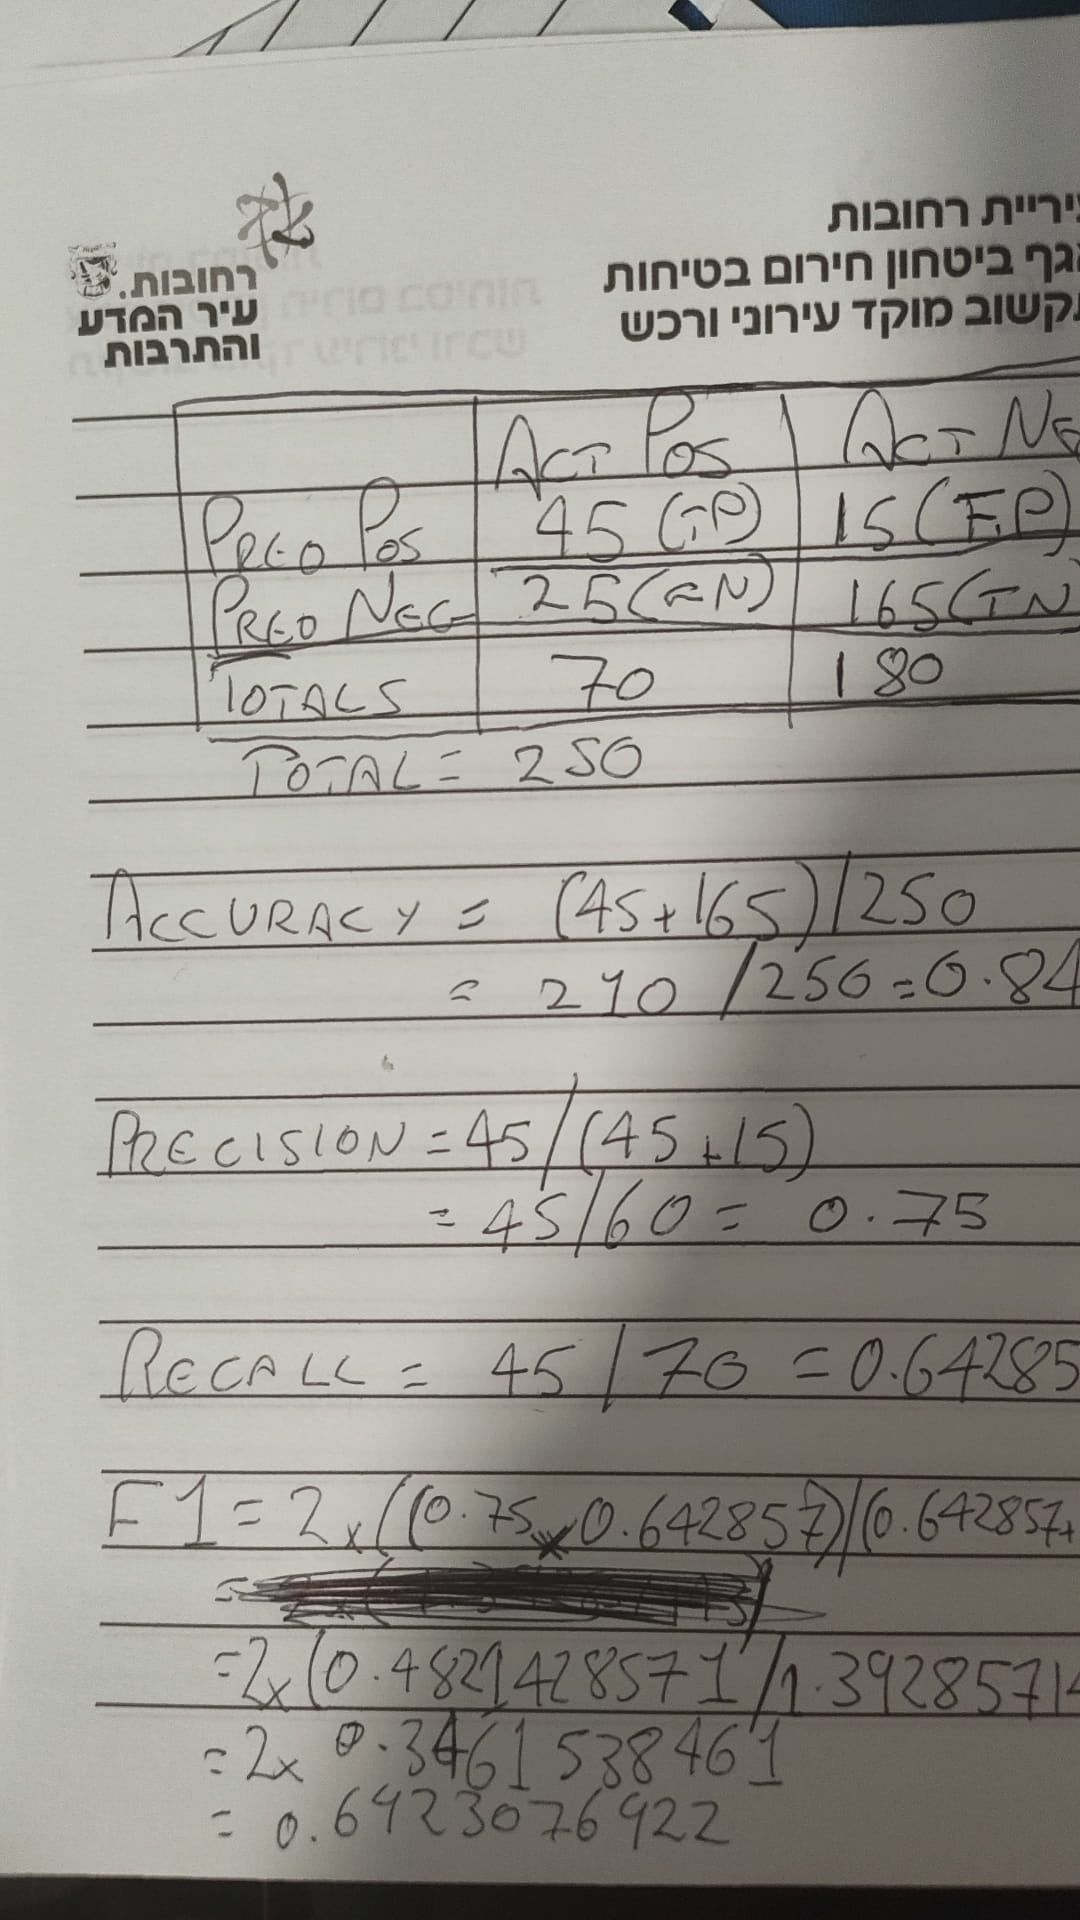

In [47]:
display(Image(filename="Classification_Metrics.jpeg"))

==============================

<h1>K-Nearest Neighbours</h1>

<h4>a</h4>

In [21]:
knn_tickets = np.array([[2, 80], [9, 15], [6, 40]])
tickets_min = np.array([0, 0])
tickets_max = np.array([10, 100])

scaled_knn_tickets = (knn_tickets - tickets_min) / (tickets_max - tickets_min)

knn_cancelled = ['No', 'Yes', '?']
knn_y = np.array([0 if c == 'No' else 1 if c == 'Yes' else np.nan for c in knn_cancelled])

print('Scaled = ', scaled_knn_tickets)
print('Target Array y =', knn_y)

Scaled =  [[0.2  0.8 ]
 [0.9  0.15]
 [0.6  0.4 ]]
Target Array y = [ 0.  1. nan]


<h4>b</h4>

In [22]:
knn_new = [0.6, 0.4]
knn_cust_a = [0.2, 0.8]
knn_cust_b = [0.9, 0.15]

knn_dist_a = math.sqrt((knn_new[0] - knn_cust_a[0])**2 + (knn_new[1] - knn_cust_a[1])**2)
knn_dist_b = math.sqrt((knn_new[0] - knn_cust_b[0])**2 + (knn_new[1] - knn_cust_b[1])**2)

print('Distance to Customer A from New Customer is ', knn_dist_a)
print('Distance to Customer B from New Customer is ', knn_dist_b)

Distance to Customer A from New Customer is  0.565685424949238
Distance to Customer B from New Customer is  0.39051248379533277


<h4>c</h4>

In [48]:
knn_classes = {'A': 'No', 'B': 'Yes'}

if knn_dist_a < knn_dist_b:
    knn_nearest = 'Customer A'
    knn_predicted_class = knn_classes['A']
else:
    knn_nearest = 'Customer B'
    knn_predicted_class = knn_classes['B']

print('Closer to:', knn_nearest)
print('Predicted class:', knn_predicted_class)

Closer to: Customer B
Predicted class: Yes


<h3>Breaking a tie</h3>

To break a 2–2 tie in KNN where K=4, the most common approach would be to use distance-weighted voting, where closer neighbors contribute more weight to the decision. Alternatively, reduce k to 3 to drop the furthest neighbor, or fall back to picking the class with the higher overall frequency in the dataset.

<h1>Support Vector Machines</h1>

<h3>Which side · how far · support vector</h3>

<h4>a</h4>

In [31]:
svm_p =(10, 2) 
svm_q = (3, 3)
svm_w1 = 6
svm_w2 = 8
svm_b = -48

svm_p_val = (svm_w1 * svm_p[0]) + (svm_w2 * svm_p[1]) + svm_b

print('Applicant P Value: ', svm_p_val)
if svm_p_val > 0:
    print("Applicant P is on the POSITIVE side of the boundary.")
elif svm_p_val < 0:
    print("Applicant P is on the NEGATIVE side of the boundary.")
else:
    print("Applicant P is exactly ON the boundary line.")

print('-------------------')

svm_q_val = (svm_w1 * svm_q[0]) + (svm_w2 * svm_q[1]) + svm_b

print('Applicant Q Value: ', svm_q_val)

if svm_q_val > 0:
    print("Applicant Q is on the POSITIVE side of the boundary.")
elif svm_q_val < 0:
    print("Applicant Q is on the NEGATIVE side of the boundary.")
else:
    print("Applicant Q is exactly ON the boundary line.")


Applicant P Value:  28
Applicant P is on the POSITIVE side of the boundary.
-------------------
Applicant Q Value:  -6
Applicant Q is on the NEGATIVE side of the boundary.


<h4>b</h4>

In [44]:
svm_w_norm = np.sqrt(svm_w1**2 + svm_w2**2)
svm_p_dist = ((svm_w1 * svm_p[0]) + (svm_w2 * svm_p[1]) + svm_b) / svm_w_norm
svm_q_dist = ((svm_w1 * svm_q[0]) + (svm_w2 * svm_q[1]) + svm_b) / svm_w_norm
svm_q_dist_positive = svm_raw_q_dist * -1
print('W Norm = ', svm_w_norm)
print('Applicant P distance from boundary: ', svm_p_dist)
print('Applicant Q distance from boundary: ', svm_q_dist_positive)

W Norm =  10.0
Applicant P distance from boundary:  2.8
Applicant Q distance from boundary:  0.6


<h4>c</h4>

Applicant Q is likely to be a support vector as it is closer - 0.6 data points - from the boundary when compared to Applicant P (2.8 data points).